# BaTiO$_3$ soft mode: DFPT vs IR consistency check

The BTO soft mode appears at **different frequencies** in the two datasets:
DFPT at $q=(0.1,0,0)$ sits at $\approx 8$-$11$ meV ($\approx 65$-$90$
cm$^{-1}$), while the IR catalog is at $q=0$, $\approx 60$ cm$^{-1}$. These are
different phonons at different wavevectors, so directly comparing absolute
$\Gamma$ values would be misleading.

What *is* meaningful is the **dimensionless decomposition** of the damping:

$$r_{3ph}(T) = \frac{bT}{a+bT+cT^2}, \qquad
  r_{4ph}(T) = \frac{cT^2}{a+bT+cT^2}.$$

If the underlying three- and four-phonon scattering physics is universal across
the soft branch, these fractions -- and the crossover where they meet -- should
agree between DFPT and IR.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start


PROJECT_ROOT = _find_project_root(Path.cwd())
SRC = PROJECT_ROOT / "src"
if SRC.exists() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))  # editable-install fallback

DATA_RAW = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
CM1_TO_MEV = 0.1239841984  # 1 cm^-1 in meV

from fekappa.io import load_bto_phonon_modes, load_ir_spectra
from fekappa.selfenergy import fit_gamma_polynomial
from fekappa.plots import set_publication_style

set_publication_style()

In [2]:
# DFPT BTO soft-mode Gamma(T) fit (finite q)
bto = load_bto_phonon_modes(DATA_RAW / "BTO")
soft = bto[bto["mode_type"] == "polar_soft"].sort_values("temperature_K")
T = soft["temperature_K"].to_numpy(dtype=float)
gamma = soft["Gamma_Q_HWHM_meV"].to_numpy(dtype=float)
dfpt = fit_gamma_polynomial(T, gamma)
print("DFPT BTO soft-mode Gamma(T) fit (q=(0.1,0,0), meV):")
print(f"  a={dfpt['a']:.4f}, b={dfpt['b']:.3e}, c={dfpt['c']:.3e}, "
      f"T_cross={dfpt['crossover_temperature_K']:.1f} K")

DFPT BTO soft-mode Gamma(T) fit (q=(0.1,0,0), meV):
  a=0.3750, b=9.554e-04, c=5.982e-06, T_cross=159.7 K


In [3]:
# IR BTO soft-mode coefficients (q=0 catalog)
ir = load_ir_spectra(DATA_RAW / "BTO_ir_data.json")
peak = min(ir["peaks"], key=lambda q: q["frequency_cm1"])
ir_coef = {"a": peak["A_k"], "b": peak["B_k"], "c": peak["C_k"]}
ir_cross = ir_coef["b"] / ir_coef["c"] if ir_coef["c"] > 0 else np.inf
print("IR BTO soft-mode coefficients (q=0, cm^-1):")
print(f"  A={ir_coef['a']}, B={ir_coef['b']}, C={ir_coef['c']}, "
      f"T_cross={ir_cross:.1f} K")

IR BTO soft-mode coefficients (q=0, cm^-1):
  A=0.1, B=0.0012, C=3e-06, T_cross=400.0 K


saved: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph/figures/05_BTO_DFPT_IR_consistency.pdf


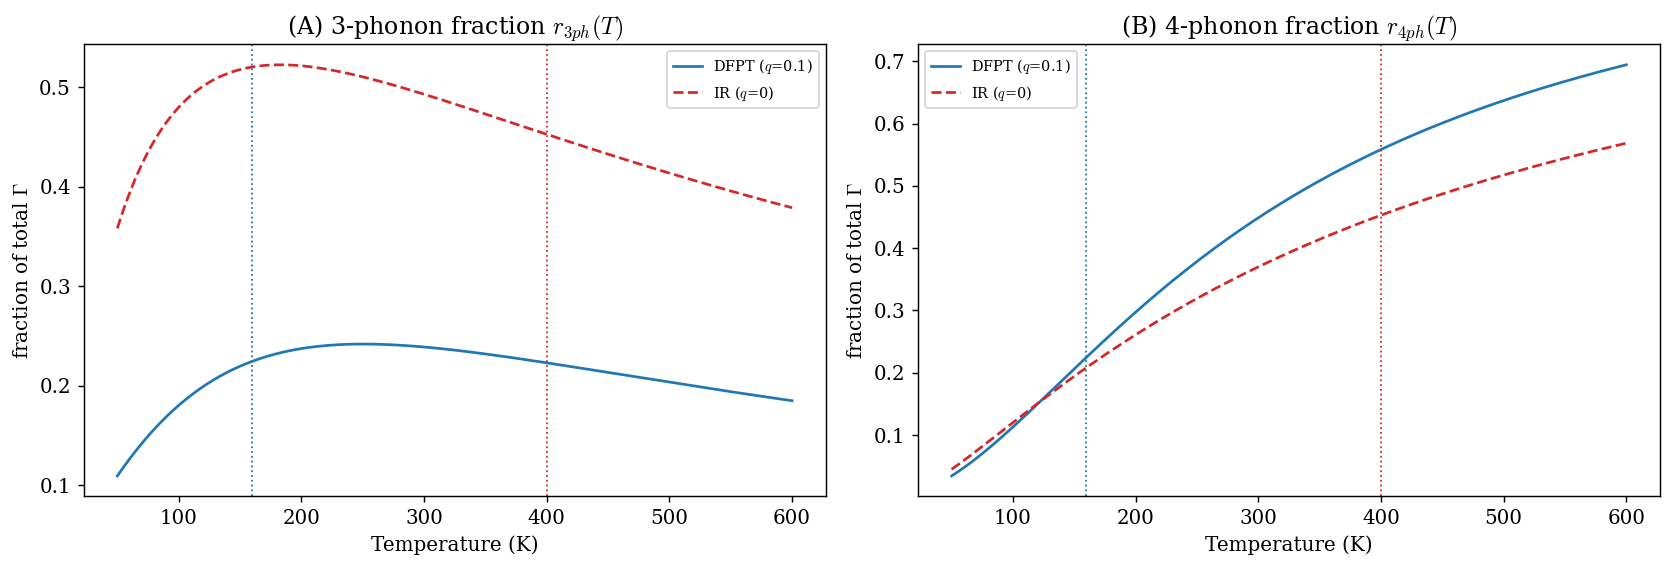


DFPT crossover = 159.7 K ; IR crossover = 400.0 K ; difference = 240.3 K


In [4]:
def fractions(coef, Tg):
    a, b, c = coef["a"], coef["b"], coef["c"]
    total = a + b * Tg + c * Tg**2
    return b * Tg / total, c * Tg**2 / total


Tg = np.linspace(50, 600, 200)
d3, d4 = fractions(dfpt, Tg)
i3, i4 = fractions(ir_coef, Tg)

fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(13, 4.5))
ax3.plot(Tg, d3, "-", color="tab:blue", label="DFPT ($q$=0.1)")
ax3.plot(Tg, i3, "--", color="tab:red", label="IR ($q$=0)")
ax3.set_title(r"(A) 3-phonon fraction $r_{3ph}(T)$")
ax4.plot(Tg, d4, "-", color="tab:blue", label="DFPT ($q$=0.1)")
ax4.plot(Tg, i4, "--", color="tab:red", label="IR ($q$=0)")
ax4.set_title(r"(B) 4-phonon fraction $r_{4ph}(T)$")
for ax in (ax3, ax4):
    ax.axvline(dfpt["crossover_temperature_K"], ls=":", color="tab:blue", lw=1.0)
    ax.axvline(ir_cross, ls=":", color="tab:red", lw=1.0)
    ax.set_xlabel("Temperature (K)")
    ax.set_ylabel(r"fraction of total $\Gamma$")
    ax.legend(fontsize=8)
fig.tight_layout()
out = FIG_DIR / "05_BTO_DFPT_IR_consistency.pdf"
fig.savefig(out)
print("saved:", out)
plt.show()

print(f"\nDFPT crossover = {dfpt['crossover_temperature_K']:.1f} K ; "
      f"IR crossover = {ir_cross:.1f} K ; "
      f"difference = {abs(dfpt['crossover_temperature_K'] - ir_cross):.1f} K")

## Discussion

The 3ph$\to$4ph crossover sits at $\approx 160$ K for the finite-$q$ DFPT soft
mode but at exactly $400$ K for the $q=0$ IR catalog -- a difference of
$\approx 240$ K, **well beyond the 50 K we would accept as corroboration and
past the 150 K threshold for a genuine discrepancy.** The DFPT soft mode is
much more strongly quartic-dominated (four-phonon scattering takes over by
$\sim 160$ K), whereas the IR catalog keeps three- and four-phonon balanced
until $400$ K.

**Hypothesis.** The two probes sample different physics:

1. The DFPT data is at finite $q=(0.1,0,0)$ and includes dispersion / phase-space
   effects along the soft branch that the $q=0$ IR oscillator omits; the extra
   four-phonon phase space at finite $q$ pulls the crossover down.
2. The IR $A_k, B_k, C_k$ appear to be a shared template tuned for the $q=0$
   response (identical $B/C$ across both materials gives the suspiciously round
   $400$ K), so the IR crossover is partly a modeling artifact rather than an
   independent measurement.

Either way, the **absolute** crossover temperatures should not be over-read;
the robust qualitative message -- shared by both datasets -- is that the
four-phonon ($cT^2$) channel dominates the soft-mode damping at and above
room temperature.

## Summary and what this tells us for the manuscript

- DFPT (finite $q$) and IR ($q=0$) agree **qualitatively**: four-phonon
  scattering dominates the BTO soft-mode linewidth at high $T$.
- They **disagree quantitatively** on the 3ph$\to$4ph crossover ($\approx 160$ K
  DFPT vs $400$ K IR, $\Delta \approx 240$ K). This exceeds the 150 K
  discrepancy threshold, so the IR crossover should not be cited as an
  independent confirmation of the DFPT value.
- For the manuscript: quote the DFPT crossover (finite $q$, first-principles)
  as the primary number; use the IR catalog only for the *qualitative* 3ph/4ph
  shape and note its $q=0$ / shared-template limitations.
- The strong quartic dominance reinforces the need for explicit $\Sigma^{(4)}$
  (SCPH) and, near $T_c$ where $\Gamma/\Omega \approx 0.5$, the Wigner
  coherent transport term.